# Logistic Regression – Hotel Booking Cancellation Prediction

**Assignment model 1 of 5**

This notebook trains a Logistic Regression classifier using the common training and held-out test partitions created by `notebooks/01_data_preparation.ipynb`.

- **Target:** `is_canceled` (`1` = cancelled; `0` = not cancelled)
- **Split:** shared stratified 80:20 split, `random_state=42`
- **Preprocessing:** numeric imputation + scaling; categorical imputation + one-hot encoding
- **Leakage control:** all learned preprocessing is fitted inside the pipeline using training data only
- **Evaluation:** Accuracy, AUC, Precision, Recall, F1 Score and MCC

Run the data-preparation notebook first. Then run this notebook from the project root or from the `model/` folder. This notebook does not create a new split or tune on the held-out test set.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    ConfusionMatrixDisplay,
    classification_report,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TARGET = "is_canceled"
MODEL_NAME = "Logistic Regression"


## 2. Load the common training and test partitions

In [2]:
# Locate the project root whether this notebook is run from the root or model/.
root_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next(
    (candidate.resolve() for candidate in root_candidates
     if (candidate / "data" / "train_data.csv").exists()
     and (candidate / "test_data.csv").exists()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/train_data.csv and test_data.csv. "
        "Run notebooks/01_data_preparation.ipynb first."
    )

RESULTS_DIR = REPO_ROOT / "results"
ARTIFACTS_DIR = REPO_ROOT / "model" / "artifacts"
PLOTS_DIR = RESULTS_DIR / "visualizations"
for directory in (RESULTS_DIR, ARTIFACTS_DIR, PLOTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

train_data = pd.read_csv(REPO_ROOT / "data" / "train_data.csv")
test_data = pd.read_csv(REPO_ROOT / "test_data.csv")

if TARGET not in train_data.columns or TARGET not in test_data.columns:
    raise KeyError(f"Both data files must contain target column {TARGET!r}.")
if list(train_data.columns) != list(test_data.columns):
    raise ValueError("Training and test columns do not match or are in a different order.")
if set(train_data[TARGET].unique()) != {0, 1} or set(test_data[TARGET].unique()) != {0, 1}:
    raise ValueError("Expected binary target values 0 and 1 in both partitions.")

X_train = train_data.drop(columns=[TARGET]).copy()
y_train = train_data[TARGET].astype(int).copy()
X_test = test_data.drop(columns=[TARGET]).copy()
y_test = test_data[TARGET].astype(int).copy()

print(f"Project root: {REPO_ROOT}")
print(f"Training set: {X_train.shape[0]:,} rows × {X_train.shape[1]} predictors")
print(f"Test set:     {X_test.shape[0]:,} rows × {X_test.shape[1]} predictors")
print("Training target distribution:")
display(y_train.value_counts().sort_index().rename(index={0: "Not cancelled (0)", 1: "Cancelled (1)"}).to_frame("records"))
print("Test target distribution:")
display(y_test.value_counts(normalize=True).sort_index().mul(100).round(2).rename(index={0: "Not cancelled (0)", 1: "Cancelled (1)"}).to_frame("percent"))


Project root: /mnt/data/ML-Assignment-2-work/ML-Assignment-2
Training set: 69,916 rows × 28 predictors
Test set:     17,480 rows × 28 predictors
Training target distribution:


,records
is_canceled,
Not cancelled (0),50696
Cancelled (1),19220


Test target distribution:


,percent
is_canceled,
Not cancelled (0),72.51
Cancelled (1),27.49


## 3. Define training-only preprocessing and the classifier

Numerical predictors are imputed with the **training median** and standardised. Categorical predictors are imputed with the constant `Unknown` and one-hot encoded. `handle_unknown='ignore'` allows categories that occur only in the test partition to be handled safely.

The class distribution is not equal (approximately 72.5% not cancelled and 27.5% cancelled after the documented cleaning). For this Logistic Regression baseline, `class_weight='balanced'` gives the minority class greater influence during fitting. Predictions use the estimator's default 0.5 probability threshold; the threshold is not selected using the test set.

In [3]:
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

if not numeric_features and not categorical_features:
    raise ValueError("No usable predictors were found.")

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features),
    ],
    remainder="drop",
)

classifier = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=1500,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", classifier),
])

print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print("Classifier configuration:")
print(classifier)


Numeric features (17): ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Categorical features (11): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'agent', 'customer_type']
Classifier configuration:
LogisticRegression(class_weight='balanced', max_iter=1500, random_state=42)


## 4. Train the model

In [4]:
# Fit the complete pipeline on training data only.
start_time = time.time()
model_pipeline.fit(X_train, y_train)
training_seconds = time.time() - start_time

print(f"Training completed in {training_seconds:.2f} seconds.")
print(f"Number of transformed predictors: {model_pipeline.named_steps['preprocessor'].transform(X_train.iloc[:1]).shape[1]:,}")


Training completed in 1.86 seconds.
Number of transformed predictors: 570


## 5. Evaluate on the held-out test set

In [5]:
# Generate hard predictions and class-1 probabilities from the untouched test set.
y_pred_train = model_pipeline.predict(X_train)
y_pred = model_pipeline.predict(X_test)
y_probability_train = model_pipeline.predict_proba(X_train)[:, 1]
y_probability = model_pipeline.predict_proba(X_test)[:, 1]

# The assignment's six required test metrics. Class 1 (cancelled) is the positive class.
test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "AUC": roc_auc_score(y_test, y_probability),
    "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
    "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
    "F1": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred),
}

train_metrics = {
    "Accuracy": accuracy_score(y_train, y_pred_train),
    "AUC": roc_auc_score(y_train, y_probability_train),
    "Precision": precision_score(y_train, y_pred_train, pos_label=1, zero_division=0),
    "Recall": recall_score(y_train, y_pred_train, pos_label=1, zero_division=0),
    "F1": f1_score(y_train, y_pred_train, pos_label=1, zero_division=0),
    "MCC": matthews_corrcoef(y_train, y_pred_train),
}

metric_table = pd.DataFrame({"Metric": list(test_metrics), "Training": list(train_metrics.values()), "Test": list(test_metrics.values())})
metric_table[["Training", "Test"]] = metric_table[["Training", "Test"]].astype(float).round(4)
display(metric_table)

# Maintain one comparison row per model so future notebooks can append their own results.
comparison_path = RESULTS_DIR / "model_comparison.csv"
new_row = pd.DataFrame([{"Model": MODEL_NAME, **test_metrics}])
if comparison_path.exists():
    existing = pd.read_csv(comparison_path)
    if "Model" in existing.columns:
        existing = existing[existing["Model"] != MODEL_NAME]
        comparison = pd.concat([existing, new_row], ignore_index=True)
    else:
        comparison = new_row
else:
    comparison = new_row
comparison.to_csv(comparison_path, index=False, float_format="%.6f")

# Save per-model train/test diagnostics and test predictions for reproducibility.
pd.DataFrame([
    {"Dataset": "Train", **train_metrics},
    {"Dataset": "Test", **test_metrics},
]).to_csv(RESULTS_DIR / "logistic_regression_metrics.csv", index=False, float_format="%.6f")
pd.DataFrame({
    "actual_is_canceled": y_test.to_numpy(),
    "predicted_is_canceled": y_pred,
    "predicted_probability_cancelled": y_probability,
}).to_csv(RESULTS_DIR / "logistic_regression_test_predictions.csv", index=False)

print(f"Comparison results saved to: {comparison_path.relative_to(REPO_ROOT)}")


,Metric,Training,Test
0,Accuracy,0.7764,0.7734
1,AUC,0.8688,0.8656
2,Precision,0.5632,0.5595
3,Recall,0.8314,0.8254
4,F1,0.6715,0.6669
5,MCC,0.5337,0.5266


Comparison results saved to: results/model_comparison.csv


## 6. Confusion matrix

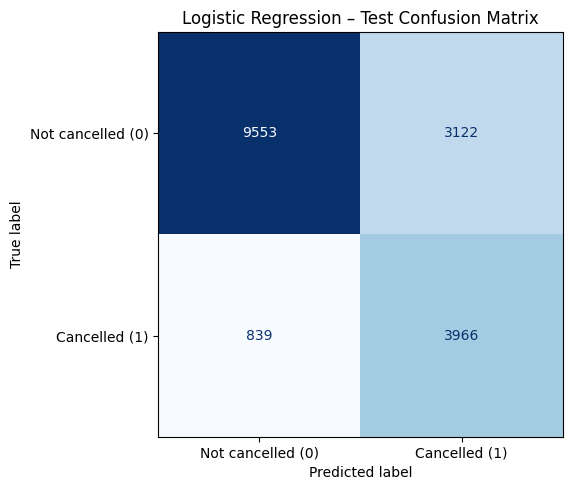

Saved: results/visualizations/logistic_regression_confusion_matrix.png
Classification report (test set):
                   precision    recall  f1-score   support

Not cancelled (0)     0.9193    0.7537    0.8283     12675
    Cancelled (1)     0.5595    0.8254    0.6669      4805

         accuracy                         0.7734     17480
        macro avg     0.7394    0.7895    0.7476     17480
     weighted avg     0.8204    0.7734    0.7839     17480



In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not cancelled (0)", "Cancelled (1)"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=ax,
)
ax.set_title("Logistic Regression – Test Confusion Matrix")
plt.tight_layout()
confusion_path = PLOTS_DIR / "logistic_regression_confusion_matrix.png"
plt.savefig(confusion_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {confusion_path.relative_to(REPO_ROOT)}")

print("Classification report (test set):")
print(classification_report(y_test, y_pred, target_names=["Not cancelled (0)", "Cancelled (1)"], zero_division=0, digits=4))


## 7. Model-specific visualisation: influential coefficients

,Feature,Coefficient
15,numeric__required_car_parking_spaces,-4.5389
238,categorical__assigned_room_type_I,-2.0895
285,categorical__agent_Agent_152,-2.0050
220,categorical__reserved_room_type_A,-1.8013
157,categorical__country_NZL,-1.7441
536,categorical__agent_Agent_69,-1.6276
229,categorical__reserved_room_type_P,1.5392
240,categorical__assigned_room_type_P,1.5392
533,categorical__agent_Agent_66,1.5409
374,categorical__agent_Agent_281,1.5510


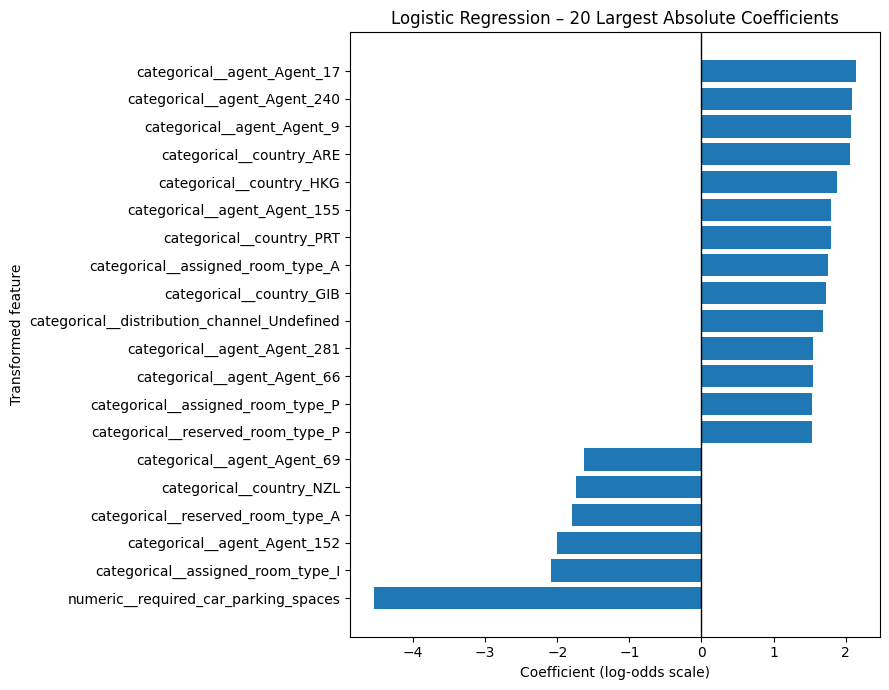

Saved: results/visualizations/logistic_regression_top_coefficients.png


In [7]:
# Logistic Regression coefficients indicate direction and magnitude on the model's log-odds scale.
feature_names = model_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefficients = model_pipeline.named_steps["classifier"].coef_.ravel()
coefficient_table = pd.DataFrame({"Feature": feature_names, "Coefficient": coefficients})
coefficient_table["Absolute coefficient"] = coefficient_table["Coefficient"].abs()
coefficient_table = coefficient_table.sort_values("Absolute coefficient", ascending=False)
top_coefficients = coefficient_table.head(20).sort_values("Coefficient")

display(top_coefficients[["Feature", "Coefficient"]].round(4))
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_coefficients["Feature"], top_coefficients["Coefficient"])
ax.axvline(0, linewidth=1, color="black")
ax.set_title("Logistic Regression – 20 Largest Absolute Coefficients")
ax.set_xlabel("Coefficient (log-odds scale)")
ax.set_ylabel("Transformed feature")
plt.tight_layout()
coefficient_path = PLOTS_DIR / "logistic_regression_top_coefficients.png"
plt.savefig(coefficient_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {coefficient_path.relative_to(REPO_ROOT)}")


## 8. Save the fitted pipeline and model configuration

In [8]:
# The serialized pipeline includes the fitted imputer, scaler, encoder and classifier.
model_path = ARTIFACTS_DIR / "logistic_regression_pipeline.joblib"
joblib.dump(model_pipeline, model_path)

model_configuration = {
    "model": MODEL_NAME,
    "target": TARGET,
    "random_state": RANDOM_STATE,
    "train_test_split": "80:20 stratified; generated in 01_data_preparation.ipynb",
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "preprocessing": {
        "numeric_imputer": "median",
        "numeric_scaler": "StandardScaler",
        "categorical_imputer": "constant: Unknown",
        "categorical_encoder": "OneHotEncoder(handle_unknown=ignore)",
    },
    "classifier": {
        "C": 1.0,
        "solver": "lbfgs",
        "max_iter": 1500,
        "class_weight": "balanced",
        "threshold": 0.5,
    },
    "test_metrics": {key: float(value) for key, value in test_metrics.items()},
    "training_seconds": float(training_seconds),
}
config_path = ARTIFACTS_DIR / "logistic_regression_config.json"
config_path.write_text(json.dumps(model_configuration, indent=2))

print(f"Saved fitted pipeline: {model_path.relative_to(REPO_ROOT)}")
print(f"Saved configuration: {config_path.relative_to(REPO_ROOT)}")


Saved fitted pipeline: model/artifacts/logistic_regression_pipeline.joblib
Saved configuration: model/artifacts/logistic_regression_config.json


## 9. Evidence-based observations

In [9]:
print("Logistic Regression – observations based on this run")
print(f"• Test accuracy: {test_metrics['Accuracy']:.4f}; test AUC: {test_metrics['AUC']:.4f}.")
print(f"• For cancelled bookings (class 1), precision: {test_metrics['Precision']:.4f}, recall: {test_metrics['Recall']:.4f}, and F1: {test_metrics['F1']:.4f}.")
print(f"• Test MCC: {test_metrics['MCC']:.4f}; this summarises the quality of binary predictions while accounting for all four confusion-matrix outcomes.")
accuracy_gap = train_metrics["Accuracy"] - test_metrics["Accuracy"]
auc_gap = train_metrics["AUC"] - test_metrics["AUC"]
print(f"• Train–test accuracy gap: {accuracy_gap:+.4f}; train–test AUC gap: {auc_gap:+.4f}.")
if abs(auc_gap) < 0.03 and abs(accuracy_gap) < 0.03:
    print("• The train/test gaps are small in this run; there is no strong sign of a large generalisation gap from these two measures.")
elif auc_gap > 0.05 or accuracy_gap > 0.05:
    print("• Training metrics exceed test metrics noticeably; this may indicate some overfitting and should be compared with the other models.")
else:
    print("• The train/test gap should be considered alongside the other models; it is not, by itself, conclusive evidence of overfitting.")
print("• The model uses class_weight='balanced'; precision and recall should be interpreted together because improving minority-class recall can affect precision.")
print("• Do not declare an overall winner yet. Compare all five classifiers on this exact held-out test partition.")


Logistic Regression – observations based on this run
• Test accuracy: 0.7734; test AUC: 0.8656.
• For cancelled bookings (class 1), precision: 0.5595, recall: 0.8254, and F1: 0.6669.
• Test MCC: 0.5266; this summarises the quality of binary predictions while accounting for all four confusion-matrix outcomes.
• Train–test accuracy gap: +0.0030; train–test AUC gap: +0.0032.
• The train/test gaps are small in this run; there is no strong sign of a large generalisation gap from these two measures.
• The model uses class_weight='balanced'; precision and recall should be interpreted together because improving minority-class recall can affect precision.
• Do not declare an overall winner yet. Compare all five classifiers on this exact held-out test partition.


## 10. Files produced

- `results/model_comparison.csv` – test-set metrics for the models completed so far
- `results/logistic_regression_metrics.csv` – training and test metrics for this model
- `results/logistic_regression_test_predictions.csv` – test labels, predictions and cancellation probabilities
- `results/visualizations/logistic_regression_confusion_matrix.png`
- `results/visualizations/logistic_regression_top_coefficients.png`
- `model/artifacts/logistic_regression_pipeline.joblib` – fitted preprocessing + model pipeline
- `model/artifacts/logistic_regression_config.json` – model configuration and test metrics

**Academic integrity:** Review the code, understand the choices, and be prepared to explain the preprocessing, class weighting, metrics and results in your own words. The remaining models must use the same train/test files and training-only preprocessing principle.